# Tổng hợp phát hiện — Calibration: hiệu chỉnh mô hình nhân quả đuôi (20 mã)

Gom các phát hiện từ `01_hyperparameters`, `02_factor_adjusted_ease`, `03_extremal_granger`.

| # | Phát hiện | Hệ quả |
|---|---|---|
| 1 | GJR/EGARCH tốt hơn theo BIC ở 14/20 mã nhưng kết quả đuôi không đổi (đồng thuận 0,97); $K = 1$ nhân tố; chọn $k = \lfloor n^{0,35}\rfloor = 14$ | Siêu tham số có cơ sở dữ liệu |
| 2 | Khử nhân tố trước EASE là bắt buộc; hệ số có điều kiện thị trường tốt nhất khi có cạnh thật (SID 0,032 so với 0,059) | Quy trình EASE hiệu chỉnh |
| 3 | Sau khử nhân tố, phụ thuộc đuôi còn lại nằm trong ngân hàng và Vingroup | Cấu trúc ngành, chưa có chiều chắc chắn |
| 4 | Granger trong đuôi: bootstrap hợp lệ chỉ ở trễ 1; theo ngưỡng mô phỏng còn ~5 cặp lan truyền cú sập (GAS → VHM lặp lại ở trễ 1 và 3) | Nhân quả theo thời gian thưa |

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "calibration"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

from scipy import stats
TAB = ROOT / "report" / "table"
def read(name, folder=FOLDER, **kw):
    path = TAB / folder / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Thiếu {path.relative_to(ROOT)} — chạy các notebook chi tiết của giai đoạn trước.")
    return pd.read_csv(path, encoding="utf-8-sig", **kw)
P = len(SYMBOLS); OFF = ~np.eye(P, dtype=bool)
SEC = np.array([U.SECTOR[s] for s in SYMBOLS])
def sector_blocks(M):
    """Trung bình hệ số theo khối ngành (ngành nguồn × ngành đích), bỏ đường chéo."""
    rows = [(SEC[i], SEC[j], M[i, j]) for i in range(P) for j in range(P) if i != j and not np.isnan(M[i, j])]
    d = pd.DataFrame(rows, columns=["nguon", "dich", "v"]).groupby(["nguon", "dich"]).v.mean().unstack()
    return d.reindex(index=U.SECTORS, columns=U.SECTORS)

import calibration as C
z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")[SYMBOLS]
n = len(z); KC = CT.default_k(n, 0.35)
print(f"n = {n}, k hiệu chỉnh = {KC}")

n = 2118, k hiệu chỉnh = 14


## Phát hiện 1 — Siêu tham số chọn từ dữ liệu

**Tính gì:** (a) ΔBIC của 4 dạng GARCH; (b) Ahn–Horenstein $\mathrm{ER}(k) = \mu_k/\mu_{k+1}$ cho số nhân tố; (c) SID của EASE (có điều kiện thị trường) theo $\nu$ trên dữ liệu
mô phỏng khớp với dữ liệu thật (một nhân tố + DAG thưa).

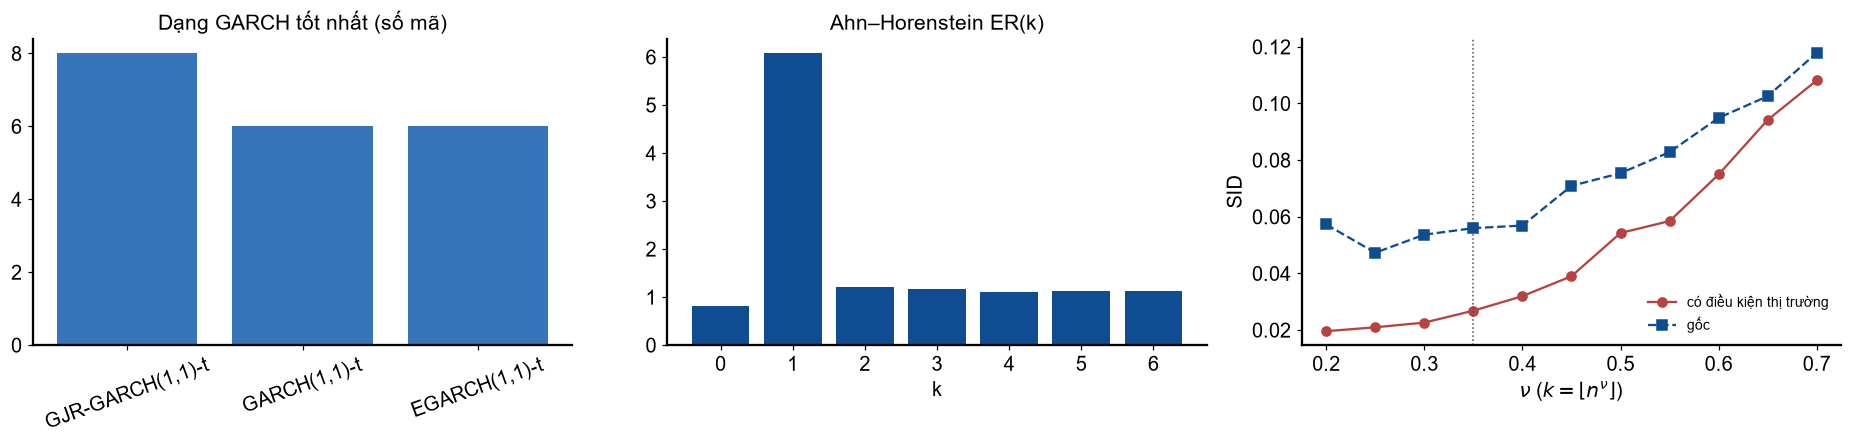

In [2]:
dbic = read("01_garch_dbic", index_col=0)
ah = read("01_ahn_horenstein", index_col=0)
ks = read("01_k_calibrated_sim").groupby(["phuong_phap", "nu"]).SID.mean().unstack(0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
best = dbic.idxmin(axis=1).value_counts()
axes[0].bar(best.index, best.values, color=PAL["blue_secondary"]); axes[0].set_title("Dạng GARCH tốt nhất (số mã)"); axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(ah.index, ah.ER, color=PAL["blue_main"]); axes[1].set_xlabel("k"); axes[1].set_title("Ahn–Horenstein ER(k)")
axes[2].plot(ks.index, ks["dieu_kien"], "o-", color=PAL["red_strong"], label="có điều kiện thị trường")
axes[2].plot(ks.index, ks["tho"], "s--", color=PAL["blue_main"], label="gốc")
axes[2].axvline(0.35, color=PAL["gray_dark"], ls=":", lw=1); axes[2].set_xlabel(r"$\nu$ ($k=\lfloor n^\nu\rfloor$)"); axes[2].set_ylabel("SID"); axes[2].legend(fontsize=9)
U.finalize_figure(fig, "finding_1_hyperparameters", folder=FOLDER); plt.show()

### Phân tích
- GJR-GARCH-t thắng ở 8 mã, EGARCH-t ở 6 (bất động sản), GARCH-t ở 6; nhưng thứ tự EASE với dạng tốt nhất đồng thuận 0,968 với GARCH-t — lựa chọn GARCH **không quan trọng** cho kết quả đuôi.
- ER đạt cực đại rõ ở $k = 1$ (6,07): một nhân tố thị trường chiếm 41% phương sai.
- SID tăng đơn điệu theo $\nu$; EASE có điều kiện tốt hơn EASE gốc ở mọi $\nu$. Chọn $\nu = 0{,}35$ ($k = 14$): SID gần tối ưu, thứ tự đã ổn định.

## Phát hiện 2 — Khử nhân tố trước EASE là bắt buộc

**Tính gì:** 5 phương pháp (gốc; loại thị trường LOO; LOO + ngành; PCA một nhân tố trên tương quan Kendall; hệ số có điều kiện thị trường
$\tilde\Psi = \tfrac12 + \tfrac12(\Psi^E - b)/(1 - b)$) trên 60 bộ dữ liệu dưới $H_0$ (không cạnh) và 60 bộ dưới $H_1$ (cạnh thưa).

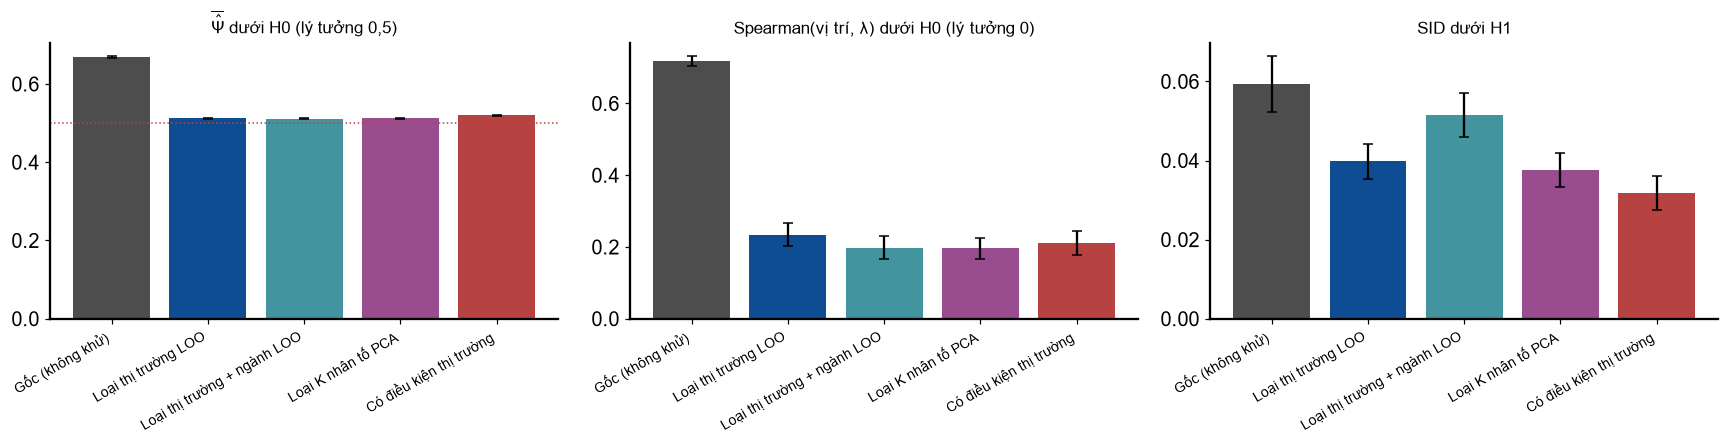

,psi_TB,cung_nganh,khac_nganh,rho_lambda
phuong_phap,,,,
Gốc (không khử),0.691,0.746,0.679,0.854
Loại thị trường LOO,0.568,0.588,0.564,0.441
Loại thị trường + ngành LOO,0.555,0.607,0.543,0.116
Loại K nhân tố PCA,0.566,0.578,0.564,0.035
Có điều kiện thị trường,0.568,0.635,0.554,0.680


In [3]:
sim = read("02_deconfounding_sim")
METH = list(C.DECONF_METHODS); names = [C.DECONF_LABELS[m] for m in METH]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cm = [PAL["gray_dark"], PAL["blue_main"], PAL["teal"], PAL["violet"], PAL["red_strong"]]
for ax, (col, h, title, ref) in zip(axes, [("psi_TB", "H0", r"$\overline{\hat\Psi}$ dưới H0 (lý tưởng 0,5)", 0.5),
                                           ("rho_lambda", "H0", "Spearman(vị trí, λ) dưới H0 (lý tưởng 0)", 0),
                                           ("SID", "H1", "SID dưới H1", None)]):
    d = sim[sim.gia_thuyet == h].groupby("phuong_phap")[col].agg(["mean", "sem"]).reindex(METH)
    ax.bar(range(5), d["mean"], yerr=d["sem"], color=cm, capsize=3)
    if ref is not None:
        ax.axhline(ref, color=PAL["red_strong"], ls=":", lw=1)
    ax.set_xticks(range(5), names, rotation=30, ha="right", fontsize=9); ax.set_title(title, fontsize=11)
U.finalize_figure(fig, "finding_2_deconfounding", folder=FOLDER); plt.show()
read("02_real_methods", index_col=0)[["psi_TB", "cung_nganh", "khac_nganh", "rho_lambda"]].round(3)

### Phân tích
- Không khử: thứ tự giả theo tải (ρ = 0,72 dưới $H_0$; 0,85 trên dữ liệu thật). Mọi phương pháp khử đưa $\overline{\hat\Psi}$ về ~0,51 và ρ về ~0,2.
- Khi có cạnh thật, **hệ số có điều kiện thị trường** cho SID thấp nhất (0,032). Loại thêm nhân tố ngành bằng LOO phản tác dụng (0,051): ngành 2–4 mã là biến đại diện nhiều nhiễu.
- Trên dữ liệu thật, PCA một nhân tố xoá gần hết thứ tự theo tải (ρ = 0,04); phương pháp có điều kiện vẫn còn ρ = 0,68 — dữ liệu có cấu trúc ngoài một nhân tố.

## Phát hiện 3 — Phụ thuộc đuôi còn lại nằm trong ngành

**Tính gì:** ma trận hệ số có điều kiện thị trường $\tilde\Psi$ ($k = 14$) trung bình theo khối ngành; các hệ số lớn nhất và khoảng bootstrap khối 90% của chúng.

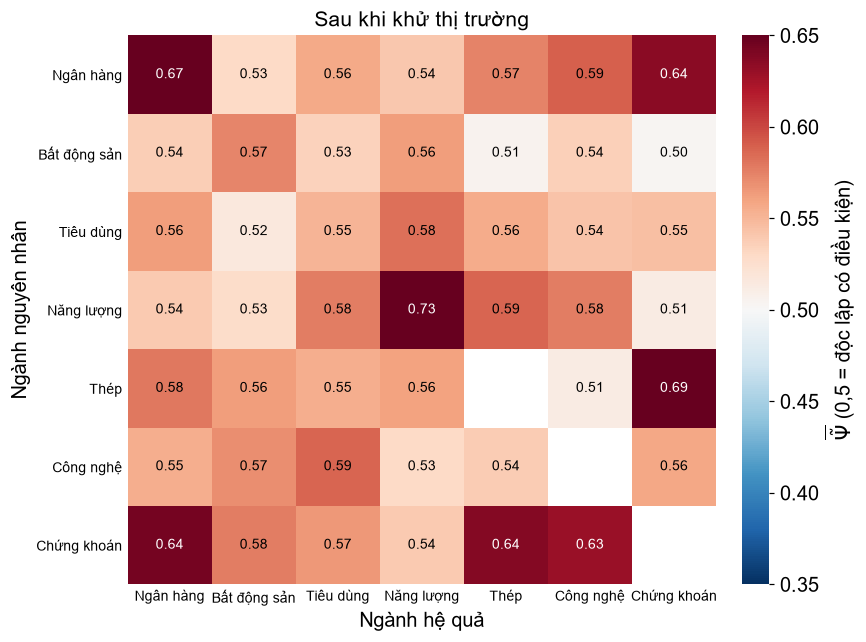

,nganh,psi_dk,q05,q95,D,D_q05,D_q95,co_chieu
cap,,,,,,,,
MBB→TCB,Ngân hàng → Ngân hàng,0.873,0.791,0.913,0.089,0.002,0.151,True
MBB→CTG,Ngân hàng → Ngân hàng,0.819,0.765,0.905,0.022,-0.068,0.110,False
VHM→VIC,Bất động sản → Bất động sản,0.802,0.720,0.894,0.061,-0.025,0.149,False
CTG→MBB,Ngân hàng → Ngân hàng,0.798,0.738,0.889,-0.022,-0.110,0.068,False
TCB→MBB,Ngân hàng → Ngân hàng,0.784,0.723,0.850,-0.089,-0.151,-0.002,True
TCB→VPB,Ngân hàng → Ngân hàng,0.761,0.662,0.798,0.102,-0.018,0.187,False
CTG→BID,Ngân hàng → Ngân hàng,0.761,0.674,0.835,0.047,-0.055,0.153,False
MBB→STB,Ngân hàng → Ngân hàng,0.759,0.620,0.822,0.046,-0.090,0.104,False
MBB→SSI,Ngân hàng → Chứng khoán,0.753,0.633,0.807,0.024,-0.114,0.095,False


In [4]:
Madj = C.adjusted_tail_coef_matrix(z, k=KC)["adj"]
blk = sector_blocks(Madj.values)
fig, ax = plt.subplots(figsize=(8, 6))
U.make_heatmap(ax, blk, cmap="RdBu_r", vmin=0.35, vmax=0.65, fmt="{:.2f}", annot_fontsize=9, tick_fontsize=9,
               cbar_label=r"$\overline{\tilde\Psi}$ (0,5 = độc lập có điều kiện)", title="Sau khi khử thị trường")
ax.set_xlabel("Ngành hệ quả"); ax.set_ylabel("Ngành nguyên nhân")
U.finalize_figure(fig, "finding_3_residual_sectors", folder=FOLDER); plt.show()
read("02_top_conditional", index_col=0)[["nganh", "psi_dk", "q05", "q95", "D", "D_q05", "D_q95", "co_chieu"]].round(3)

### Phân tích
- Khối ngân hàng → ngân hàng là khối duy nhất còn đậm sau khi khử thị trường; trong 12 hệ số lớn nhất, 9 là ngân hàng → ngân hàng (MBB→TCB 0,87, MBB→CTG 0,82…),
  cùng cặp Vingroup VHM↔VIC (0,80/0,74).
- Chỉ MBB–TCB có bất đối xứng với khoảng 90% không chứa 0 ($D$ = +0,09), sát ngưỡng và chưa hiệu chỉnh đa so sánh — gợi ý MBB → TCB, chưa phải bằng chứng.

## Phát hiện 4 — Granger trong đuôi: lan truyền cú sập theo ngày tồn tại nhưng thưa

**Tính gì:** $\hat\Gamma_{X\to Y}(p) = \frac{1}{|S|}\sum_{t\in S}\max_{h\le p}\tilde F_Y(Y_{t+h})$ trên các phiên $X_t$ cực trị (đuôi dưới) trong khi $Y_t$ và thị trường chưa cực trị,
so với mức nền $b$ (Bodik & Pasche 2024, arXiv:2407.09632). Kiểm tra kích thước kiểm định bằng mô phỏng $H_0$ (không có trễ), rồi dùng ngưỡng $\Delta$ ở phân vị 99,9% dưới $H_0$.

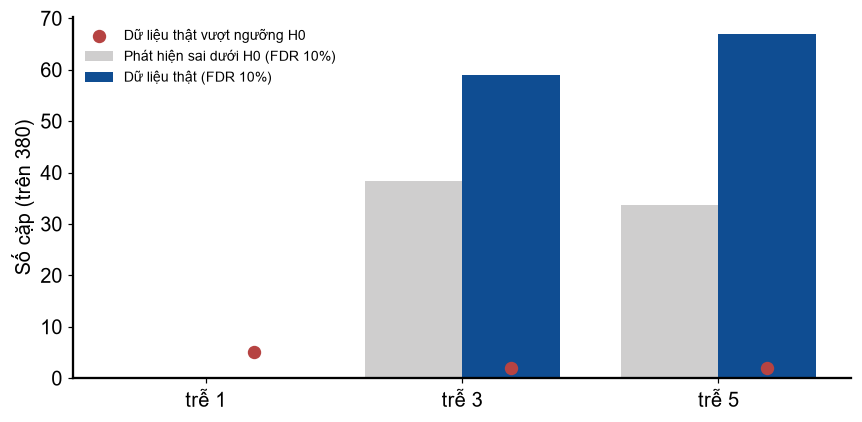

,tre,cause,effect,gamma,baseline,delta
0,1,VCB,BID,0.699,0.385,0.314
4,1,PLX,BID,0.690,0.386,0.304
2,1,MBB,STB,0.685,0.381,0.304
3,1,GAS,VHM,0.654,0.374,0.280
1,1,VCB,MWG,0.642,0.371,0.271
6,3,GAS,VHM,0.909,0.693,0.216
5,3,TCB,HPG,0.895,0.705,0.190
7,5,MBB,VIC,0.933,0.796,0.137
8,5,MBB,VHM,0.920,0.810,0.110


In [5]:
size = read("03_size_check", index_col=[0, 1]).groupby(level=0).mean()
summ = read("03_granger_summary", index_col=0)
strong = read("03_granger_beyond_null")
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(3); w = 0.38
ax.bar(x - w / 2, size["so_cap_q<0,1"], w, color=PAL["neutral"], label="Phát hiện sai dưới H0 (FDR 10%)")
ax.bar(x + w / 2, summ.loc[["lower, p=1", "lower, p=3", "lower, p=5"], "so_cap_q<0,1"], w, color=PAL["blue_main"], label="Dữ liệu thật (FDR 10%)")
ax.scatter(x + w / 2, summ.loc[["lower, p=1", "lower, p=3", "lower, p=5"], "so_cap_vuot_nguong_H0"], color=PAL["red_strong"], zorder=3, s=60,
           label="Dữ liệu thật vượt ngưỡng H0")
ax.set_xticks(x, ["trễ 1", "trễ 3", "trễ 5"]); ax.set_ylabel("Số cặp (trên 380)"); ax.legend(fontsize=9)
U.finalize_figure(fig, "finding_4_extremal_granger", folder=FOLDER); plt.show()
strong[["tre", "cause", "effect", "gamma", "baseline", "delta"]].sort_values(["tre", "delta"], ascending=[True, False]).round(3)

### Phân tích
- Ở trễ 3–5, bootstrap khối báo 59–67 cặp qua FDR nhưng chính nó tạo 29–52 phát hiện sai dưới $H_0$ — không đáng tin. Theo ngưỡng hiệu chỉnh bằng mô phỏng chỉ còn
  5 cặp ở trễ 1 (VCB→BID, PLX→BID, MBB→STB, GAS→VHM, VCB→MWG) và 2 cặp ở mỗi trễ 3, 5.
- **GAS → VHM** lặp lại ở trễ 1 và 3 — tín hiệu nhất quán nhất; nguồn lan truyền chủ yếu là ngân hàng lớn và năng lượng.

## Kết luận Calibration
1. Quy trình hiệu chỉnh: GARCH-t (kết quả vững với dạng GARCH) → khử một nhân tố thị trường (hệ số có điều kiện) → EASE với $k = \lfloor n^{0,35}\rfloor$ → bổ sung Granger trong đuôi
   với ngưỡng hiệu chỉnh bằng mô phỏng.
2. Sau hiệu chỉnh: lan truyền đồng thời **không xác định được chiều** giữa các mã (phụ thuộc còn lại là trong ngành); lan truyền **theo ngày** có ở một số ít cặp, đáng chú ý GAS → VHM.
3. Hướng tiếp theo: kiểm chứng ngoài mẫu các cặp Granger; mô hình nhân tố nhiều tầng (thị trường + ngành) ước lượng trên nhiều mã hơn để khử nhân tố ngành chính xác hơn.